# Module 2: Tabular Foundation Models on Public Building Energy Data

In this notebook we predict the **energy use intensity (EUI)** of real buildings from a few basic facts
(building type, size, age, location), using **TabPFN**, a foundation model for tables.
We compare it with classic machine-learning models from scikit-learn.

**Learning goals**

- Understand how a tabular foundation model differs from classic models such as random forests: it does not
  "train" on your data, it **reads your training rows as context** (in-context learning).
- Explore a public building energy benchmarking dataset and avoid a common trap: **data leakage**.
- Compare accuracy with cross-validation, and see where tabular FMs shine: **small datasets**.

**Runs locally** in the `fm4ues` conda environment (see the repository README). A GPU is used when available.
Every main step is timed, and a runtime summary is shown at the end.

## 0. Setup and GPU check

In [1]:
import time
import platform
import logging
import warnings
from contextlib import contextmanager
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Keep the output tidy: hide a harmless Windows-only PyTorch notice and library warnings
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

# Repository root = the first parent folder that contains requirements.txt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
CACHE = ROOT / "data" / "cache"          # downloaded data goes here (ignored by git)
CACHE.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() and torch.cuda.device_count() > 0 else "cpu"
# DEVICE = "cpu"   # <- uncomment to compare with CPU speed
print(f"Python  : {platform.python_version()}")
print(f"PyTorch : {torch.__version__}")
print(f"Device  : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(f"Data dir: {CACHE.relative_to(ROOT)}")

np.random.seed(0)
torch.manual_seed(0)

# --- Timing helper -------------------------------------------------------
TIMINGS = {}  # step name -> seconds

@contextmanager
def timed(step):
    # Measure the wall-clock time of a block of code and store it in TIMINGS.
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    yield
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    TIMINGS[step] = time.perf_counter() - start
    print(f"[time] {step}: {TIMINGS[step]:.1f} s")

plt.rcParams["figure.figsize"] = (12, 4)

Python  : 3.11.18
PyTorch : 2.11.0+cu128
Device  : cuda (Quadro RTX 6000)
Data dir: data\cache


## 1. What is a tabular foundation model?

Most building data lives in **tables**: one row per building, one column per property (type, floor area, year built, ...).
The classic approach is to **train** a model, such as a random forest or gradient boosting, on that table.
Training means adjusting the model's internal parameters until it fits your rows.

A **tabular foundation model** works differently:

1. It was pretrained **once**, on millions of *synthetic* (computer-generated) tables, to become good at the general task
   "given some example rows with answers, predict the answer for new rows".
2. On your data it does **not change its parameters**. You hand it your training rows *and* the new rows together,
   and it predicts in a single forward pass. This is called **in-context learning**, the same idea as giving
   a large language model a few examples in the prompt.

We use **TabPFN v2** (*Prior-data Fitted Network*, Prior Labs, published in *Nature* in 2025).
It works best for tables up to about 10,000 rows and 500 columns, which covers many building datasets.

| | Classic model (e.g. random forest) | Tabular FM (TabPFN) |
| :--- | :--- | :--- |
| Learns from your data by | training (fitting parameters) | reading rows as context |
| `.fit()` does | the actual training | mostly stores the data |
| `.predict()` does | a quick calculation | the actual work (a transformer forward pass, GPU helps) |
| Hyperparameter tuning | often needed | usually not needed |

**Licence note:** TabPFN **v2** weights are openly available (Prior Labs License, based on Apache 2.0).
Newer versions (2.5 and later) are more accurate but need a free registration at Prior Labs and are for
non-commercial use. See "Things to try" at the end.

## 2. Load the data

We use the **Chicago Energy Benchmarking** dataset from the [City of Chicago Data Portal](https://data.cityofchicago.org/Environment-Sustainable-Development/Chicago-Energy-Benchmarking/xq83-jr8c).
Large buildings in Chicago (over 50,000 ft²) must report their yearly energy use. We take the **2022** reports.

**Target:** site energy use intensity, `site_eui_kbtu_sq_ft`: yearly energy use per floor area, in kBtu per square foot
(1 kBtu/ft² ≈ 3.15 kWh/m²).

In [2]:
DATA_FILE = CACHE / "chicago_benchmarking_2022.csv"
API_URL = "https://data.cityofchicago.org/resource/xq83-jr8c.csv"

with timed("1. Load building data (download on first run)"):
    if not DATA_FILE.exists():
        import requests
        print("Downloading Chicago Energy Benchmarking 2022 ...")
        resp = requests.get(API_URL, params={"$where": "data_year=2022", "$limit": 50000}, timeout=120)
        resp.raise_for_status()
        DATA_FILE.write_text(resp.text, encoding="utf-8")
    raw = pd.read_csv(DATA_FILE)

print(f"{len(raw):,} rows, {raw.shape[1]} columns")
print(raw["reporting_status"].value_counts())

[time] 1. Load building data (download on first run): 0.0 s
3,613 rows, 30 columns
reporting_status
Submitted Data    2645
Not Submitted      732
Exempt             236
Name: count, dtype: int64


### Choosing features, and avoiding data leakage

The table has 30 columns, but we must **not** use all of them.
Columns such as `electricity_use_kbtu`, `natural_gas_use_kbtu`, `energy_star_score`, `chicago_energy_rating` or
`ghg_intensity_kg_co2e_sq_ft` are all **calculated from the measured energy use**, which is exactly what we want to predict.
Using them would be cheating, a mistake called **data leakage**: the model would look perfect in testing and fail in real use.

We only keep facts that are known **before** measuring energy use:

| Feature | Meaning |
| :--- | :--- |
| `building_type` | Primary property type (rare types grouped into "Other") |
| `log_floor_area` | Gross floor area, on a log scale (sizes range from 50,000 to millions of ft²) |
| `year_built` | Construction year |
| `of_buildings` | Number of buildings on the property |
| `latitude`, `longitude` | Location within Chicago |

In [3]:
# Keep buildings that actually reported data
df = raw[raw["reporting_status"].str.contains("Submitted", na=False)].copy()

cols = ["primary_property_type", "gross_floor_area_buildings_sq_ft", "year_built", "of_buildings",
        "latitude", "longitude", "site_eui_kbtu_sq_ft"]
df = df[cols].dropna()

# Remove implausible EUI values (typing errors, empty buildings)
df = df[(df["site_eui_kbtu_sq_ft"] > 5) & (df["site_eui_kbtu_sq_ft"] < 500)].reset_index(drop=True)

# Group building types with fewer than 20 buildings into "Other"
counts = df["primary_property_type"].value_counts()
common = counts[counts >= 20].index
df["building_type"] = df["primary_property_type"].where(df["primary_property_type"].isin(common), "Other")
df["log_floor_area"] = np.log10(df["gross_floor_area_buildings_sq_ft"])

print(f"{len(df):,} buildings after cleaning")
df["building_type"].value_counts()

2,532 buildings after cleaning


building_type
Multifamily Housing          1410
Office                        325
K-12 School                   311
Other                         184
Hotel                          74
College/University             64
Senior Living Community        63
Retail Store                   37
Supermarket/Grocery Store      32
Mixed Use Property             32
Name: count, dtype: int64

## 3. Explore the data

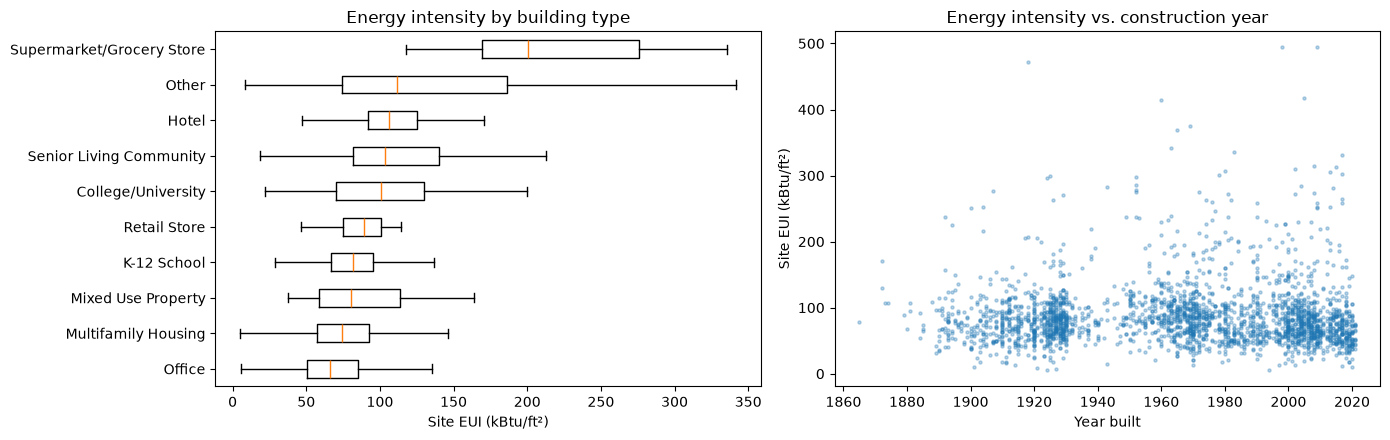

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# EUI per building type (sorted by median)
order = df.groupby("building_type")["site_eui_kbtu_sq_ft"].median().sort_values().index
axes[0].boxplot([df.loc[df["building_type"] == t, "site_eui_kbtu_sq_ft"] for t in order],
                vert=False, showfliers=False)
axes[0].set_yticks(range(1, len(order) + 1), order)
axes[0].set_xlabel("Site EUI (kBtu/ft²)")
axes[0].set_title("Energy intensity by building type")

# EUI vs. construction year
axes[1].scatter(df["year_built"], df["site_eui_kbtu_sq_ft"], s=5, alpha=0.3)
axes[1].set_xlabel("Year built")
axes[1].set_ylabel("Site EUI (kBtu/ft²)")
axes[1].set_title("Energy intensity vs. construction year")
plt.tight_layout()
plt.show()

Building type clearly matters (supermarkets and hospitals use far more energy per ft² than offices or schools),
but **within** each type the spread is large. Construction year shows almost no clear trend.
Keep this in mind: if the features do not contain the information, no model, foundation model or not, can predict well.

## 4. Prepare the table and set up a fair comparison

Models need numbers, so `building_type` is turned into one 0/1 column per type ("one-hot encoding").

To compare models fairly we use **5-fold cross-validation**: split the buildings into 5 groups, train on 4 and test
on the 5th, rotate 5 times, so that every building is predicted exactly once by a model that never saw it.

Metrics:

- **MAE** (mean absolute error, kBtu/ft²): average size of the error. Lower is better.
- **R²**: share of the variation between buildings that the model explains. 1 = perfect, 0 = no better than always predicting the average.

In [5]:
from sklearn.model_selection import KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion

numeric = ["log_floor_area", "year_built", "of_buildings", "latitude", "longitude"]
X = pd.concat([df[numeric], pd.get_dummies(df["building_type"], prefix="type", dtype=float)], axis=1)
y = df["site_eui_kbtu_sq_ft"].to_numpy()
print(f"Feature table: {X.shape[0]} buildings x {X.shape[1]} columns")

# Each entry creates a fresh, untrained model
MODELS = {
    "Average (baseline)": lambda: DummyRegressor(),
    "Linear regression":  lambda: LinearRegression(),
    "Random forest":      lambda: RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0),
    "Gradient boosting":  lambda: HistGradientBoostingRegressor(random_state=0),
    "TabPFN v2":          lambda: TabPFNRegressor.create_default_for_version(
                                      ModelVersion.V2, device=DEVICE, random_state=0),
}

kfold = KFold(n_splits=5, shuffle=True, random_state=0)

def cross_validate(make_model):
    # Return out-of-fold predictions: every building predicted by a model that never saw it.
    pred = np.zeros_like(y)
    for train_idx, test_idx in kfold.split(X):
        model = make_model().fit(X.values[train_idx], y[train_idx])
        pred[test_idx] = model.predict(X.values[test_idx])
    return pred

Feature table: 2532 buildings x 15 columns


## 5. Classic models vs. TabPFN

The first TabPFN run downloads the model weights (about 45 MB).

In [6]:
predictions, rows = {}, []
for name, make_model in MODELS.items():
    with timed(f"2. 5-fold CV: {name}"):
        predictions[name] = cross_validate(make_model)
    rows.append({"Model": name,
                 "MAE (kBtu/ft²)": mean_absolute_error(y, predictions[name]),
                 "R²": r2_score(y, predictions[name]),
                 "Time (s)": TIMINGS[f"2. 5-fold CV: {name}"]})

results = pd.DataFrame(rows).set_index("Model")
results.round(3)

[time] 2. 5-fold CV: Average (baseline): 0.0 s
[time] 2. 5-fold CV: Linear regression: 0.0 s


[time] 2. 5-fold CV: Random forest: 4.2 s


[time] 2. 5-fold CV: Gradient boosting: 1.8 s


[time] 2. 5-fold CV: TabPFN v2: 7.0 s


,MAE (kBtu/ft²),R²,Time (s)
Model,,,
Average (baseline),30.588,-0.001,0.023
Linear regression,27.609,0.232,0.013
Random forest,26.168,0.292,4.210
Gradient boosting,26.969,0.275,1.782
TabPFN v2,25.466,0.309,7.033


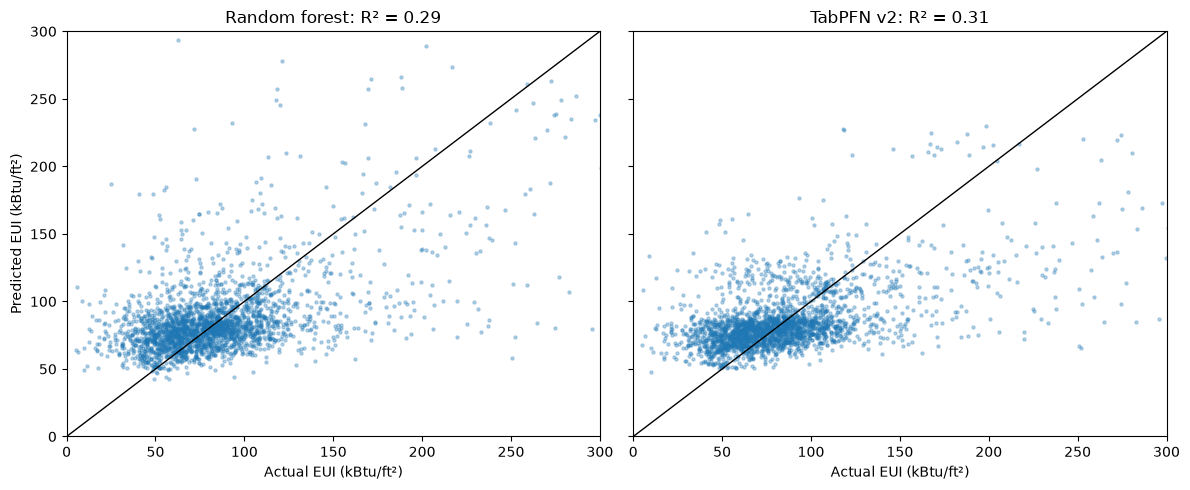

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, name in zip(axes, ["Random forest", "TabPFN v2"]):
    ax.scatter(y, predictions[name], s=5, alpha=0.3)
    ax.plot([0, 500], [0, 500], color="black", lw=1)          # perfect-prediction line
    ax.set_xlim(0, 300); ax.set_ylim(0, 300)
    ax.set_xlabel("Actual EUI (kBtu/ft²)")
    ax.set_title(f"{name}: R² = {r2_score(y, predictions[name]):.2f}")
axes[0].set_ylabel("Predicted EUI (kBtu/ft²)")
plt.tight_layout()
plt.show()

**How to read the results**

- TabPFN should be the most accurate model here, **without any tuning**. The random forest and gradient boosting
  use library defaults; with careful tuning they could close part of the gap.
- All models have a modest R² (around 0.3). The points scatter widely around the diagonal.
  Two offices of the same size and age can use very different amounts of energy, depending on occupancy,
  equipment and how the building is run. That information is simply **not in the table**.
  A better model cannot fix missing information; better features can.
- Notice the timing: TabPFN's `.fit()` is almost instant, but `.predict()` does the heavy work on the GPU.

## 6. Where tabular FMs shine: small datasets

In practice we often have data for only a few dozen buildings (one municipality, one building owner, one campus).
Here we pretend we know the EUI of only **n** buildings, train on those, and test on 500 other buildings.
Each size is repeated 5 times with different random buildings, and the errors are averaged.

[time] 3. Learning curve (7 sizes x 5 repeats x 4 models): 75.7 s


,Linear regression,Random forest,Gradient boosting,TabPFN v2
Training buildings,,,,
25,33.4,32.8,31.5,31.1
50,32.1,31.5,31.7,30.1
100,30.8,31.3,32.6,29.8
200,29.3,28.9,30.9,28.0
500,28.4,28.4,30.5,27.1
1000,28.0,27.9,29.5,26.5
2000,27.9,26.9,27.7,26.0


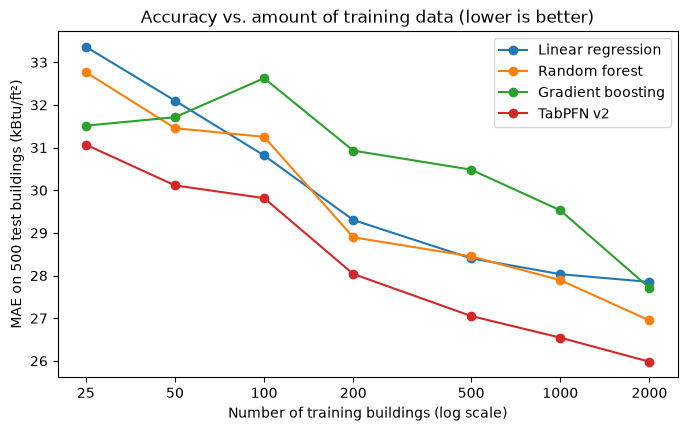

In [8]:
TRAIN_SIZES = [25, 50, 100, 200, 500, 1000, 2000]
REPEATS = 5
CURVE_MODELS = ["Linear regression", "Random forest", "Gradient boosting", "TabPFN v2"]

rng = np.random.default_rng(0)
curve = {m: {n: [] for n in TRAIN_SIZES} for m in CURVE_MODELS}

with timed("3. Learning curve (7 sizes x 5 repeats x 4 models)"):
    for rep in range(REPEATS):
        order_idx = rng.permutation(len(y))
        test_idx = order_idx[:500]                      # fixed test set for this repeat
        for n in TRAIN_SIZES:
            train_idx = order_idx[500:500 + n]
            for m in CURVE_MODELS:
                model = MODELS[m]().fit(X.values[train_idx], y[train_idx])
                curve[m][n].append(mean_absolute_error(y[test_idx], model.predict(X.values[test_idx])))

curve_mae = pd.DataFrame({m: {n: np.mean(v) for n, v in curve[m].items()} for m in CURVE_MODELS})
curve_mae.index.name = "Training buildings"
display(curve_mae.round(1))

ax = curve_mae.plot(marker="o", logx=True, figsize=(8, 4.5))
ax.set_xticks(TRAIN_SIZES, TRAIN_SIZES)
ax.minorticks_off()
ax.set_xlabel("Number of training buildings (log scale)")
ax.set_ylabel("MAE on 500 test buildings (kBtu/ft²)")
ax.set_title("Accuracy vs. amount of training data (lower is better)")
plt.show()

**How to read the curve**

- Compare models **horizontally**, not only vertically: how many buildings does each model need to reach a given error?
  TabPFN typically reaches with a few hundred buildings the accuracy that the classic models only reach with
  a few times more data. That is **data efficiency**: TabPFN learned during pretraining what typical relationships in
  tables look like, so it needs fewer examples of your problem.
- Gradient boosting struggles with very small tables. By default each leaf of its trees needs at least 20 rows,
  so with 25 buildings it can barely split the data at all. TabPFN needs no such settings.
- All curves keep going down: more buildings still help every model. A foundation model does not replace collecting data.

## 7. Runtime summary

In [9]:
timing_table = pd.Series(TIMINGS, name="seconds").round(1).to_frame()
timing_table.loc["Total (timed steps)"] = timing_table["seconds"].sum().round(1)
gpu = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only"
print(f"Hardware: {gpu}")
display(timing_table)
timing_table.assign(device=gpu).to_csv(CACHE / "module2_runtime.csv")

Hardware: Quadro RTX 6000


,seconds
1. Load building data (download on first run),0.0
2. 5-fold CV: Average (baseline),0.0
2. 5-fold CV: Linear regression,0.0
2. 5-fold CV: Random forest,4.2
2. 5-fold CV: Gradient boosting,1.8
2. 5-fold CV: TabPFN v2,7.0
3. Learning curve (7 sizes x 5 repeats x 4 models),75.7
Total (timed steps),88.7


## 8. Things to try

- **More features:** add `community_area` (neighbourhood) as a category. Does accuracy improve?
- **Leakage demo:** add `energy_star_score` as a feature and watch R² jump. Why is this result useless in practice?
- **Train on one year, test on another:** download 2021 data, train on 2021 and predict 2022.
- **Uncertainty:** TabPFN can return quantiles: `model.predict(X_test, output_type="quantiles", quantiles=[0.1, 0.5, 0.9])`.
- **Newer TabPFN:** register at [Prior Labs](https://ux.priorlabs.ai), accept the licence (non-commercial),
  set the `TABPFN_TOKEN` environment variable, and use `TabPFNRegressor(device=DEVICE)` (latest version) instead of v2.